Project title: Logistic Regression (Minor Project 3)

Name: Udeep Karmakar

Dataset name: diabetes.csv

Dataset link: https://www.kaggle.com/datasets/mragpavank/diabetes

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

sns.set_style("whitegrid")

In [7]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("diabetes.csv")
print("Shape:", df.shape)
df.head()

Saving diabetes.csv to diabetes (1).csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
print(df.info())
print("\nMissing values (as NaN):\n", df.isnull().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Missing values (as NaN):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Outcome
0    500
1    268
Name: count, dtype: int64

Percentages:
 Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


/tmp/ipykernel_1241/3451483139.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Outcome", data=df, palette="Set2")


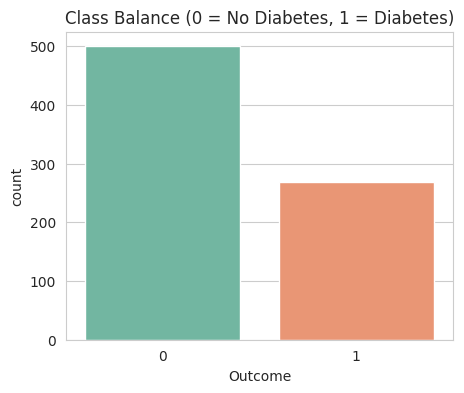

In [9]:
print(df["Outcome"].value_counts())
print("\nPercentages:\n", df["Outcome"].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(5, 4))
sns.countplot(x="Outcome", data=df, palette="Set2")
plt.title("Class Balance (0 = No Diabetes, 1 = Diabetes)")
plt.show()

In [10]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zero counts before replacing:")
print((df[zero_cols] == 0).sum())

df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("\nMissing values after replacing:")
print(df[zero_cols].isnull().sum())

Zero counts before replacing:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after replacing:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


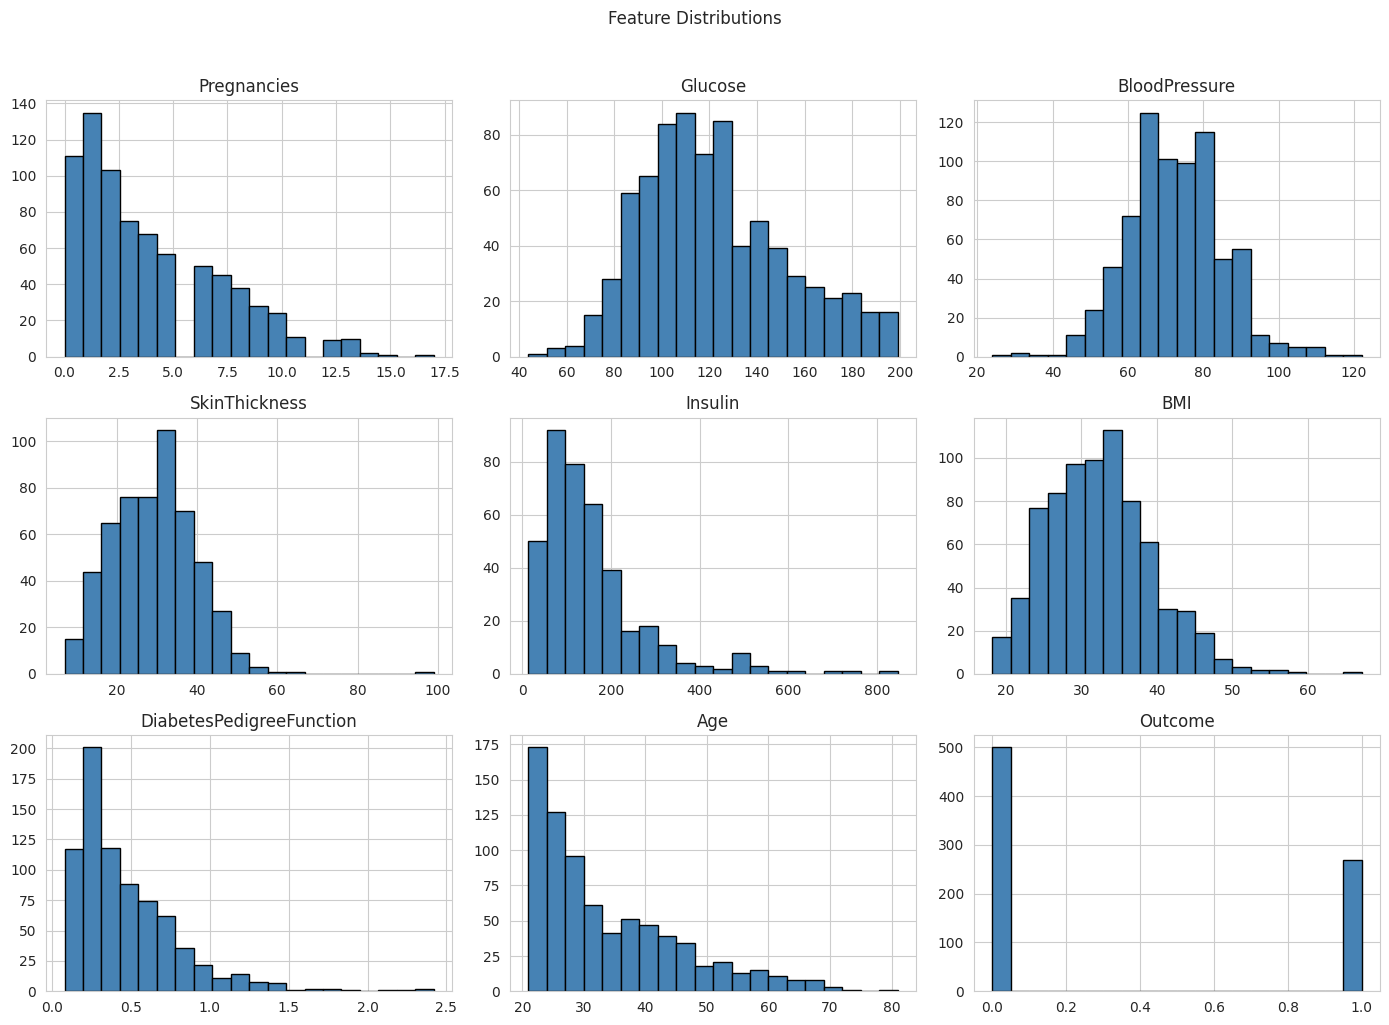

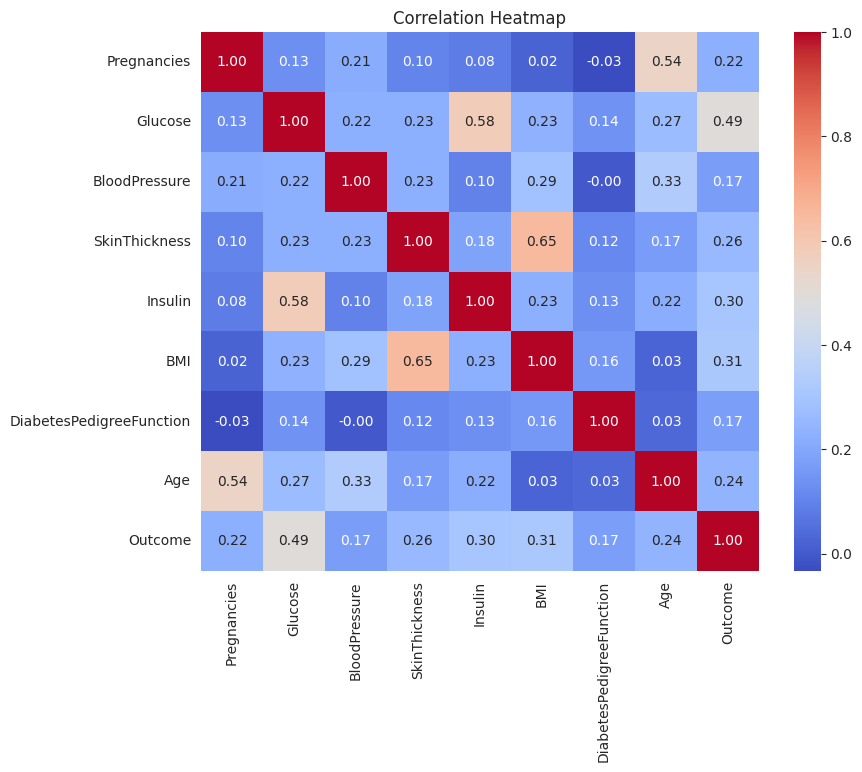

/tmp/ipykernel_1241/3154058402.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, palette="Set2", ax=ax)
/tmp/ipykernel_1241/3154058402.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, palette="Set2", ax=ax)
/tmp/ipykernel_1241/3154058402.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, palette="Set2", ax=ax)


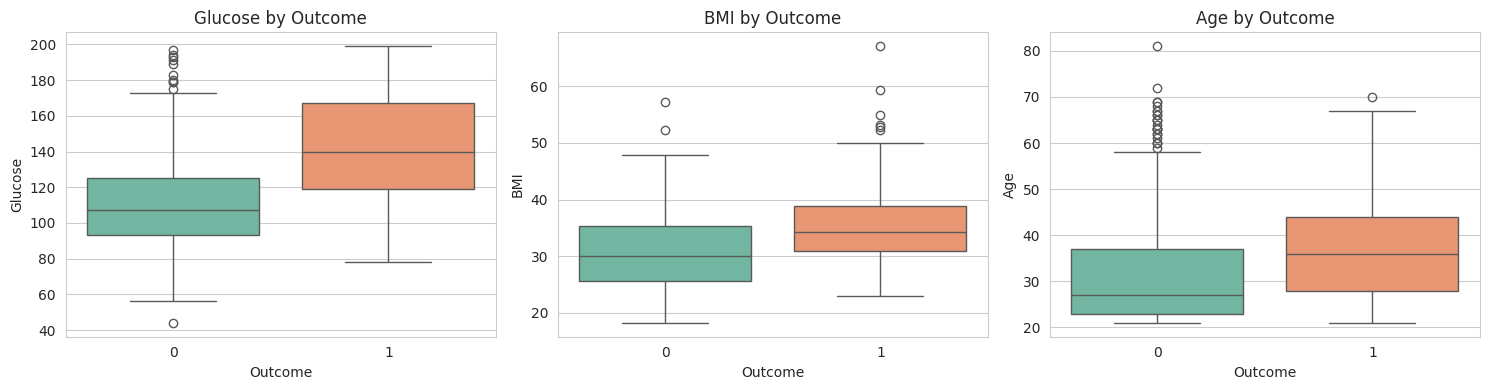

In [11]:
# Histograms of all features
df.hist(figsize=(14, 10), bins=20, color="steelblue", edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Boxplots of key features by Outcome
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.boxplot(x="Outcome", y=col, data=df, palette="Set2", ax=ax)
    ax.set_title(f"{col} by Outcome")
plt.tight_layout()
plt.show()

In [12]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)
print("\nTest class counts:\n", y_test.value_counts())

Train size: (614, 8)
Test size : (154, 8)

Test class counts:
 Outcome
0    100
1     54
Name: count, dtype: int64


In [13]:
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

pipe.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


In [14]:
y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)[:, 1]

In [15]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Result": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
    ],
    "Meaning": [
        "Overall correct predictions",
        "Reliability of positive predictions",
        "Actual positive cases detected",
        "Balance of precision and recall",
        "Overall class-separation ability",
    ],
})
metrics["Result"] = metrics["Result"].round(3)
metrics

,Metric,Result,Meaning
0,Accuracy,0.734,Overall correct predictions
1,Precision,0.603,Reliability of positive predictions
2,Recall,0.704,Actual positive cases detected
3,F1-score,0.650,Balance of precision and recall
4,ROC-AUC,0.813,Overall class-separation ability


TN = 75, FP = 25, FN = 16, TP = 38


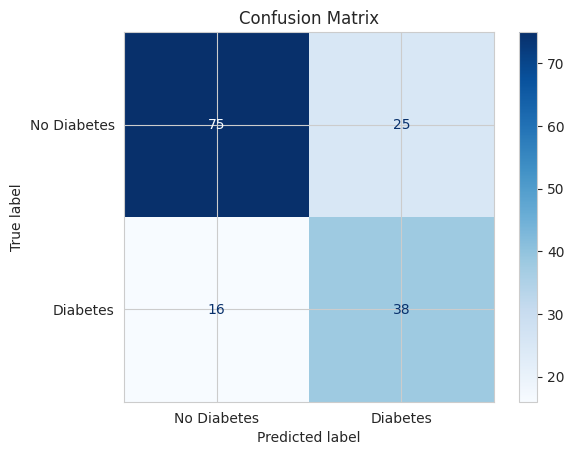

In [23]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

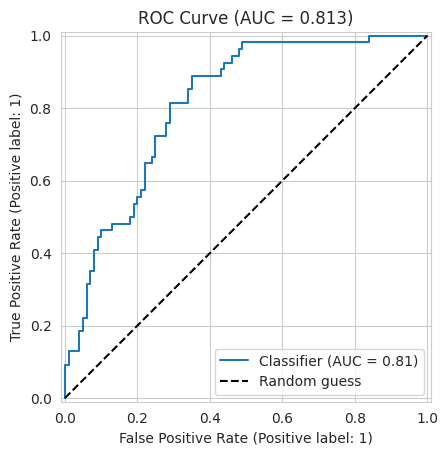

In [17]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title(f"ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.legend()
plt.show()

In [18]:
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.82      0.75      0.79       100
    Diabetes       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



,Feature,Coefficient,Odds Ratio
1,Glucose,1.183,3.266
5,BMI,0.710,2.033
0,Pregnancies,0.373,1.452
6,DiabetesPedigreeFunction,0.288,1.333
7,Age,0.186,1.205
3,SkinThickness,0.014,1.014
2,BloodPressure,-0.015,0.985
4,Insulin,-0.045,0.956


/tmp/ipykernel_1241/1261509820.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient", y="Feature", data=coef_df, palette="viridis")


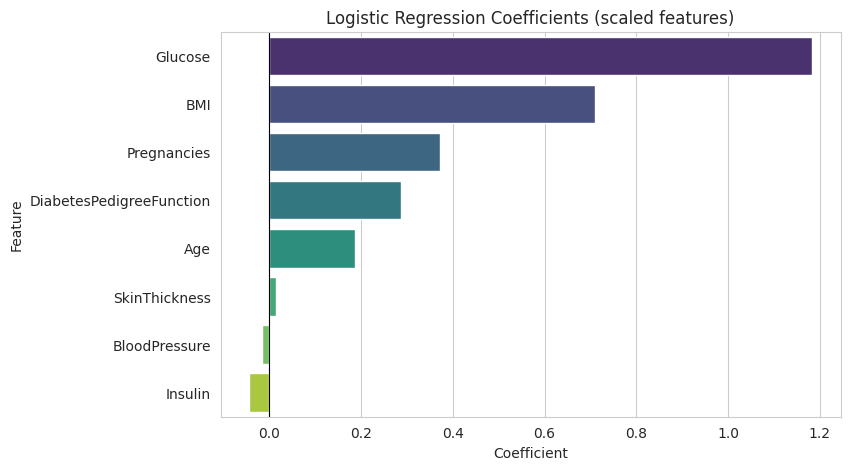

In [19]:
coef = pipe.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coef,
    "Odds Ratio": np.exp(coef),
}).sort_values("Coefficient", ascending=False)

display(coef_df.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x="Coefficient", y="Feature", data=coef_df, palette="viridis")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Coefficients (scaled features)")
plt.show()